# 03 · Generative Adversarial Networks: Sharper Samples, Harder Training

## Overview

Notebook 02 ended with a diagnosis: the VAE's samples are **realistic but over-smoothed**, because a Gaussian likelihood rewards predicting the average. In 2014 Goodfellow and colleagues proposed to drop the likelihood altogether:

> Train a **generator** $G$ that turns noise into data, and a **discriminator** $D$ that tries to tell real data from generated data. The generator improves by fooling the discriminator.

The discriminator is effectively a **learned loss function**. It is not limited to squared error, so it can penalize "blurry" frames that a pixel-wise (here, pair-wise) loss would accept. GANs went on to dominate image synthesis from 2014 to about 2020. They also showed, very visibly, how hard adversarial training is to control.

**Path through this notebook**

1. Vanilla GAN, and the failure modes it shows on our data: unstable losses and **mode collapse**.
2. Wasserstein GAN with gradient penalty (WGAN-GP): a better-behaved objective.
3. A **conditional** WGAN-GP that generates a frame for a requested variant.
4. Comparison with the VAE on the shared scorecard, and the limitations that motivate diffusion models.

## Learning objectives

1. Write the GAN minimax objective and implement alternating generator/discriminator updates.
2. Recognize mode collapse and explain why GAN losses are poor progress indicators.
3. Explain the Wasserstein distance, the Lipschitz constraint and the gradient penalty.
4. Condition a generator on a class label and verify the result with an independent classifier.

**Runtime:** about 6 minutes on a laptop CPU.

In [1]:
import sys, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
sys.path.insert(0, ".")
from ppi_dl.data import load_ppi, set_seed
from ppi_dl.metrics import Scorecard, load_scorecards
from ppi_dl.plotting import plot_pca_overlay, plot_feature_distributions

data = load_ppi("block")
Xtr, ytr = torch.tensor(data.X_train), torch.tensor(data.y_train)
D_IN, Z_DIM, N = data.n_features, 64, len(Xtr)
sc = Scorecard(data)
sc.reference()
print(data.summary())

split=block: train (3200, 4886), test (800, 4886), train class counts [1600, 1600], test class counts [400, 400]


## 1. The vanilla GAN

The two networks play a minimax game:

$$ \min_G \max_D \; \mathbb{E}_{x \sim p_{\text{data}}}\big[\log D(x)\big] + \mathbb{E}_{z \sim \mathcal{N}(0,I)}\big[\log\big(1 - D(G(z))\big)\big] $$

For a fixed $G$, the optimal discriminator is $D^*(x) = \frac{p_{\text{data}}(x)}{p_{\text{data}}(x) + p_G(x)}$. Plugging it back in shows that the generator is minimizing the **Jensen–Shannon divergence** between $p_{\text{data}}$ and $p_G$.

In practice the generator maximizes $\log D(G(z))$ (the "non-saturating" loss) rather than minimizing $\log(1 - D(G(z)))$, because the latter has vanishing gradients early in training, when $D$ easily rejects fakes.

We track progress every 5 epochs with the scorecard's quick check: `precision`, `coverage`, and the **fraction of samples the frozen classifier calls SARS-CoV-2**. A healthy generator of both variants should sit near 0.5.

In [2]:
def make_G(c_dim=0):
    return nn.Sequential(nn.Linear(Z_DIM + c_dim, 256), nn.LeakyReLU(0.2),
                         nn.Linear(256, 512), nn.LeakyReLU(0.2), nn.Linear(512, D_IN))

class Critic(nn.Module):
    """Discriminator / critic: features phi(x) -> scalar score.

    n_classes > 0 adds a *projection* term (used in Section 4): score += <embed(y), phi(x)>.
    """
    def __init__(self, d_in=D_IN, n_classes=0):
        super().__init__()
        self.phi = nn.Sequential(nn.Linear(d_in, 512), nn.LeakyReLU(0.2), nn.Linear(512, 256), nn.LeakyReLU(0.2))
        self.psi = nn.Linear(256, 1)
        self.embed = nn.Embedding(n_classes, 256) if n_classes else None
    def forward(self, x, y=None):
        h = self.phi(x)
        out = self.psi(h)
        if self.embed is not None:
            out = out + (self.embed(y) * h).sum(1, keepdim=True)
        return out

def track(G, c=None, n=800):
    with torch.no_grad():
        z = torch.randn(n, Z_DIM)
        x = G(z if c is None else torch.cat([z, c], 1)).numpy()
    return sc.quick(x)

set_seed(0)
G, D = make_G(), Critic()
opt_G = torch.optim.Adam(G.parameters(), lr=2e-4, betas=(0.5, 0.999))
opt_D = torch.optim.Adam(D.parameters(), lr=2e-4, betas=(0.5, 0.999))
bce = nn.BCEWithLogitsLoss()
ones, zeros = lambda n: torch.ones(n, 1), lambda n: torch.zeros(n, 1)

log_gan, t0 = [], time.time()
for ep in range(100):
    perm = torch.randperm(N)
    for i in range(0, N, 64):
        xr = Xtr[perm[i:i + 64]]; b = len(xr)
        xf = G(torch.randn(b, Z_DIM))
        # discriminator step: real -> 1, fake -> 0
        loss_D = bce(D(xr), ones(b)) + bce(D(xf.detach()), zeros(b))
        opt_D.zero_grad(); loss_D.backward(); opt_D.step()
        # generator step (non-saturating): make D call fakes real
        loss_G = bce(D(xf), ones(b))
        opt_G.zero_grad(); loss_G.backward(); opt_G.step()
    if ep % 5 == 4:
        log_gan.append({"epoch": ep + 1, "loss_D": loss_D.item(), "loss_G": loss_G.item(), **track(G)})
print(f"vanilla GAN trained in {time.time()-t0:.0f}s")
log_gan = pd.DataFrame(log_gan).set_index("epoch")
log_gan.round(3).iloc[::4]

vanilla GAN trained in 656s


,loss_D,loss_G,precision,coverage,frac_cov2
epoch,,,,,
5,0.453,1.367,0.231,0.009,0.340
25,0.239,4.383,0.655,0.200,0.458
45,0.288,3.092,0.709,0.222,0.996
65,0.215,3.076,0.778,0.221,1.000
85,0.482,3.856,0.855,0.266,1.000


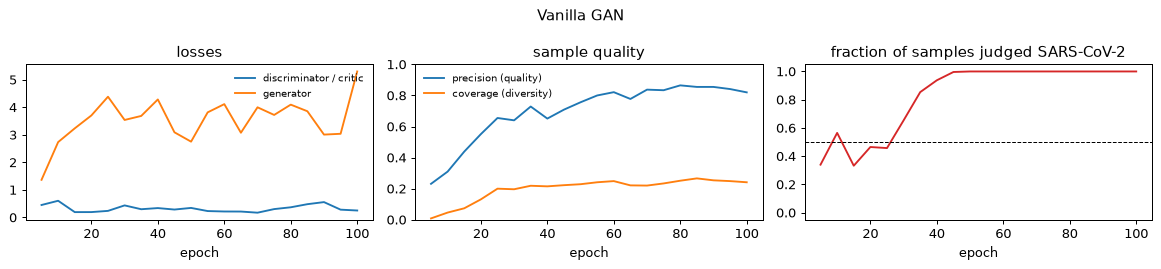

In [3]:
def plot_log(log, title):
    fig, axes = plt.subplots(1, 3, figsize=(13, 3))
    axes[0].plot(log.index, log["loss_D"], label="discriminator / critic")
    axes[0].plot(log.index, log["loss_G"], label="generator")
    axes[0].set_title("losses"); axes[0].legend(frameon=False, fontsize=8)
    axes[1].plot(log.index, log["precision"], label="precision (quality)")
    axes[1].plot(log.index, log["coverage"], label="coverage (diversity)")
    axes[1].set_ylim(0, 1); axes[1].set_title("sample quality"); axes[1].legend(frameon=False, fontsize=8)
    axes[2].plot(log.index, log["frac_cov2"], color="tab:red")
    axes[2].axhline(0.5, color="k", ls="--", lw=0.8)
    axes[2].set_ylim(-0.05, 1.05); axes[2].set_title("fraction of samples judged SARS-CoV-2")
    for ax in axes: ax.set_xlabel("epoch")
    fig.suptitle(title); fig.tight_layout()
    return fig
plot_log(log_gan, "Vanilla GAN"); plt.show()

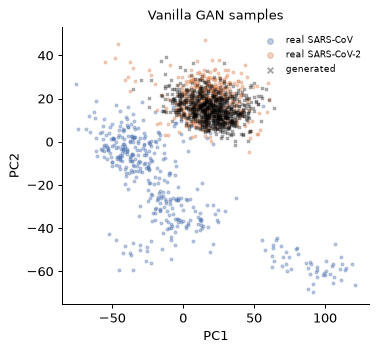

,std_ratio,mmd,precision,coverage,c2st_auc,judge_acc,nn_ratio
model,,,,,,,
real (train frames),0.993,0.009,0.64,0.799,0.854,1.0,NaN
vanilla GAN,0.564,0.170,0.84,0.241,0.980,NaN,0.884


In [4]:
with torch.no_grad():
    gan_samples = G(torch.randn(len(data.X_test), Z_DIM)).numpy()
sc.evaluate(gan_samples, name="vanilla GAN")
plot_pca_overlay(sc, gan_samples, title="Vanilla GAN samples"); plt.show()
sc.table()

## 2. What went wrong: mode collapse

The data contain (at least) two very different modes, SARS-CoV and SARS-CoV-2 frames. Check the right-hand panel above and the PCA plot: the vanilla GAN tends to settle on **one** of them. Precision can stay high (the frames it does make look real) while coverage stays low. This is **mode collapse**, the best-known GAN failure. Three things go wrong at once:

* **Nothing in the objective rewards diversity.** If one realistic frame fools $D$, $G$ can map every $z$ to it. $D$ then learns to reject that mode, $G$ jumps to another, and the two can chase each other indefinitely.
* **The losses are uninformative.** The left panel shows $D$ and $G$ losses that say little about sample quality. Unlike a VAE's ELBO, a GAN has no number that reliably goes down as samples get better.
* **Vanishing gradients.** In 4,886 dimensions the real and generated distributions barely overlap early on. The Jensen–Shannon divergence then saturates at $\log 2$, so it gives the generator almost no direction to move in.

## 3. Wasserstein GAN with gradient penalty

Arjovsky *et al.* (2017) replaced the JS divergence with the **Wasserstein-1 ("earth mover's") distance**: the minimum cost of moving probability mass from $p_G$ to $p_{\text{data}}$. It stays informative even when the two distributions do not overlap. By Kantorovich–Rubinstein duality,

$$ W(p_{\text{data}}, p_G) = \sup_{\lVert f\rVert_L \le 1} \; \mathbb{E}_{x\sim p_{\text{data}}}[f(x)] - \mathbb{E}_{x\sim p_G}[f(x)] $$

so the discriminator becomes a **critic** $f$ that outputs an unbounded score, with no sigmoid. It must be **1-Lipschitz**. Gulrajani *et al.* (2017) enforce this softly with a **gradient penalty** on points $\hat{x}$ interpolated between real and fake samples:

$$ \mathcal{L}_{\text{critic}} = \mathbb{E}[f(\tilde{x})] - \mathbb{E}[f(x)] + \lambda\,\mathbb{E}_{\hat{x}}\big[(\lVert\nabla_{\hat{x}} f(\hat{x})\rVert_2 - 1)^2\big], \qquad \lambda = 10 $$

The critic is updated several times ($n_{\text{critic}} = 5$) per generator update, so it stays close to optimal and its value approximates the Wasserstein distance. That turns the critic loss into a meaningful progress curve.

WGAN-GP trained in 62s


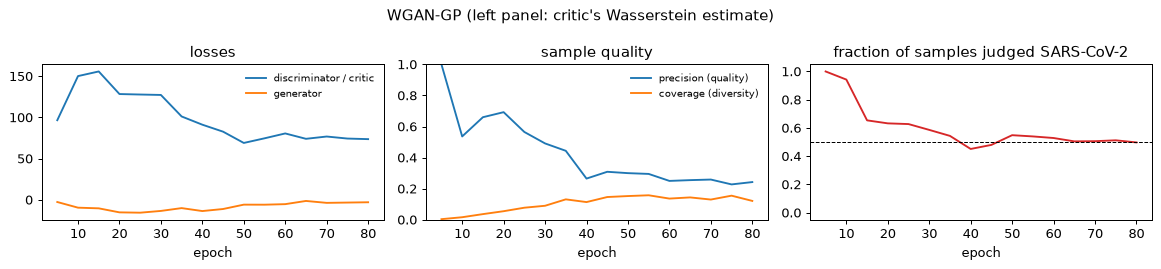

In [5]:
def gradient_penalty(score, xr, xf, y):
    eps = torch.rand(len(xr), 1)
    xi = (eps * xr + (1 - eps) * xf).requires_grad_(True)
    grad = torch.autograd.grad(score(xi, y).sum(), xi, create_graph=True)[0]
    return ((grad.norm(dim=1) - 1) ** 2).mean()

def train_wgan_gp(epochs=80, conditional=None, n_critic=5, lam=10.0, seed=0):
    """conditional: None, "concat" (label appended to critic input) or "projection"."""
    set_seed(seed)
    c_dim = 0 if conditional is None else 2
    G = make_G(c_dim)
    if conditional == "projection":
        f = Critic(n_classes=2)
        score = lambda x, y: f(x, y)
    elif conditional == "concat":
        f = Critic(d_in=D_IN + 2)
        score = lambda x, y: f(torch.cat([x, F.one_hot(y, 2).float()], 1))
    else:
        f = Critic()
        score = lambda x, y: f(x)
    gen = lambda z, y: G(z if c_dim == 0 else torch.cat([z, F.one_hot(y, 2).float()], 1))
    opt_G = torch.optim.Adam(G.parameters(), lr=1e-4, betas=(0.0, 0.9))
    opt_f = torch.optim.Adam(f.parameters(), lr=1e-4, betas=(0.0, 0.9))
    y_track = torch.arange(800) % 2
    log, step = [], 0
    for ep in range(epochs):
        perm = torch.randperm(N)
        for i in range(0, N, 64):
            idx = perm[i:i + 64]; xr, y = Xtr[idx], ytr[idx]; b = len(xr)
            xf = gen(torch.randn(b, Z_DIM), y).detach()
            w_est = score(xr, y).mean() - score(xf, y).mean()        # Wasserstein estimate
            loss_f = -w_est + lam * gradient_penalty(score, xr, xf, y)
            opt_f.zero_grad(); loss_f.backward(); opt_f.step()
            step += 1
            if step % n_critic == 0:
                loss_G = -score(gen(torch.randn(b, Z_DIM), y), y).mean()
                opt_G.zero_grad(); loss_G.backward(); opt_G.step()
        if ep % 5 == 4:
            with torch.no_grad():
                xs = gen(torch.randn(800, Z_DIM), y_track).numpy()
            entry = {"epoch": ep + 1, "loss_D": w_est.item(), "loss_G": loss_G.item(), **sc.quick(xs)}
            if c_dim:
                entry["judge_acc"] = float((sc.judge.predict(xs) == y_track.numpy()).mean())
            log.append(entry)
    G.eval()
    gen.net = G                      # keep a handle on the raw generator network
    return gen, pd.DataFrame(log).set_index("epoch")

t0 = time.time()
gen_w, log_w = train_wgan_gp()
print(f"WGAN-GP trained in {time.time()-t0:.0f}s")
fig = plot_log(log_w, "WGAN-GP (left panel: critic's Wasserstein estimate)"); plt.show()

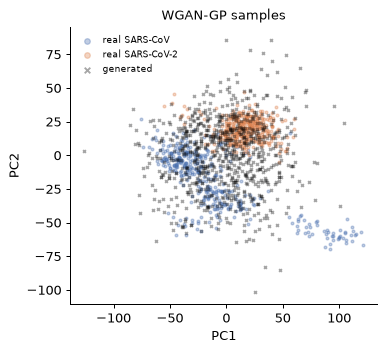

,std_ratio,mmd,precision,coverage,c2st_auc,judge_acc,nn_ratio
model,,,,,,,
real (train frames),0.993,0.009,0.640,0.799,0.854,1.0,NaN
vanilla GAN,0.564,0.170,0.840,0.241,0.980,NaN,0.884
WGAN-GP,0.784,0.023,0.266,0.136,1.000,NaN,1.442


In [6]:
with torch.no_grad():
    wgan_samples = gen_w(torch.randn(len(data.X_test), Z_DIM), None).numpy()
sc.evaluate(wgan_samples, name="WGAN-GP")
plot_pca_overlay(sc, wgan_samples, title="WGAN-GP samples"); plt.show()
sc.table()

Compare the two training runs.

* **Mode balance is fixed.** The fraction of samples judged SARS-CoV-2 settles near 0.5: both variants are generated.
* **The spread is better.** `std_ratio` and `mmd` move much closer to the reference than for the vanilla GAN or the VAE.
* **The loss means something.** After an initial rise, the critic's Wasserstein estimate falls as samples improve.
* **But precision drops.** In the PCA plot, many WGAN-GP samples land *between* the real clusters. The model has traded the vanilla GAN's "few modes, sharp samples" for "all modes, some unrealistic samples". Training longer does not fix this on our data (try it: precision stays near 0.2 at 200 epochs). This tension between **quality and coverage** is the central difficulty of GAN training.

## 4. Conditional generation

Often we want a frame **of a given variant**. The simplest approach (Mirza & Osindero, 2014) is to concatenate a one-hot label $c$ to the generator's noise *and* to the critic's input, so the critic judges "is this a realistic frame **for this label**?". The frozen judge classifier from the scorecard then checks whether we got what we asked for (`judge_acc`).

In [7]:
t0 = time.time()
gen_cat, log_cat = train_wgan_gp(conditional="concat")
print(f"concat-conditional WGAN-GP trained in {time.time()-t0:.0f}s")
y_req = torch.tensor(data.y_test)
with torch.no_grad():
    cat_samples = gen_cat(torch.randn(len(y_req), Z_DIM), y_req).numpy()
sc.evaluate(cat_samples, data.y_test, name="cWGAN-GP (concat label)")
sc.table()

concat-conditional WGAN-GP trained in 64s


,std_ratio,mmd,precision,coverage,c2st_auc,judge_acc,nn_ratio
model,,,,,,,
real (train frames),0.993,0.009,0.640,0.799,0.854,1.000,NaN
vanilla GAN,0.564,0.170,0.840,0.241,0.980,NaN,0.884
WGAN-GP,0.784,0.023,0.266,0.136,1.000,NaN,1.442
cWGAN-GP (concat label),0.802,0.022,0.209,0.129,1.000,0.538,1.469


Look at `judge_acc`: it sits near **0.5**, which is chance. The generator ignores the label. The reason is a matter of proportion: the label is 2 of the critic's 4,888 inputs. The critic can score realism perfectly well without it, so it never punishes "a SARS-CoV frame labelled SARS-CoV-2", and the generator has no reason to listen.

### The projection discriminator

Miyato & Koyama (2018) made the label impossible to ignore by building it into the critic's **output**:
$$ f(x, y) = \psi\big(\phi(x)\big) + \langle e_y,\, \phi(x)\rangle $$
where $\phi(x)$ is the critic's 256-dimensional feature vector and $e_y$ is a learned embedding of the class. The second term directly measures *how well the features of $x$ match class $y$*. The idea of conditioning by an inner product between a learned embedding and features is worth remembering: it is the core of **attention** (Notebook 05).

projection-conditional WGAN-GP trained in 339s


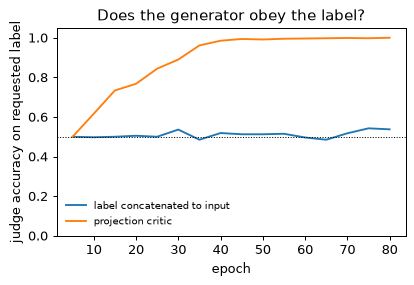

,std_ratio,mmd,precision,coverage,c2st_auc,judge_acc,nn_ratio
model,,,,,,,
real (train frames),0.993,0.009,0.640,0.799,0.854,1.000,NaN
vanilla GAN,0.564,0.170,0.840,0.241,0.980,NaN,0.884
WGAN-GP,0.784,0.023,0.266,0.136,1.000,NaN,1.442
cWGAN-GP (concat label),0.802,0.022,0.209,0.129,1.000,0.538,1.469
cWGAN-GP (projection),0.768,0.020,0.346,0.205,0.995,0.999,1.339


In [8]:
t0 = time.time()
gen_c, log_c = train_wgan_gp(conditional="projection")
print(f"projection-conditional WGAN-GP trained in {time.time()-t0:.0f}s")
with torch.no_grad():
    cgan_samples = gen_c(torch.randn(len(y_req), Z_DIM), y_req).numpy()
sc.evaluate(cgan_samples, data.y_test, name="cWGAN-GP (projection)")

fig, ax = plt.subplots(figsize=(5, 3))
ax.plot(log_cat.index, log_cat["judge_acc"], label="label concatenated to input")
ax.plot(log_c.index, log_c["judge_acc"], label="projection critic")
ax.axhline(0.5, color="k", ls=":", lw=0.8)
ax.set_ylim(0, 1.05); ax.set_xlabel("epoch"); ax.set_ylabel("judge accuracy on requested label")
ax.legend(frameon=False, fontsize=8); ax.set_title("Does the generator obey the label?"); plt.show()
sc.table()

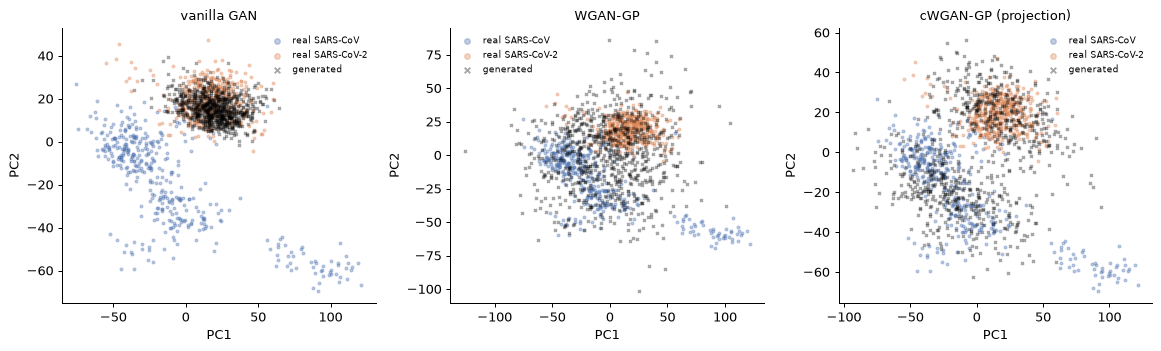

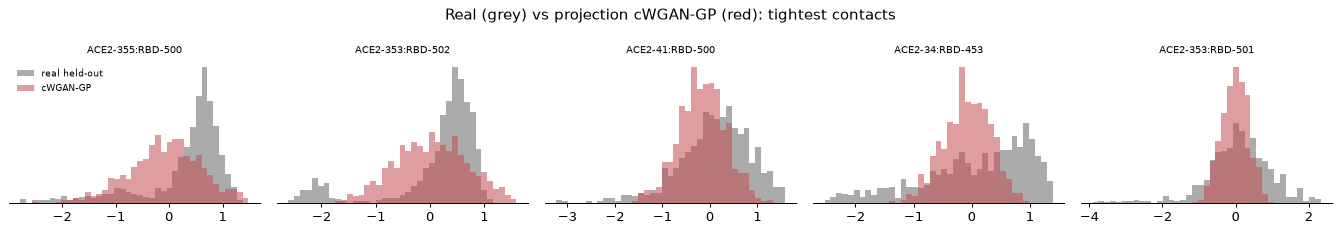

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, (X, t) in zip(axes, [(gan_samples, "vanilla GAN"), (wgan_samples, "WGAN-GP"),
                             (cgan_samples, "cWGAN-GP (projection)")]):
    plot_pca_overlay(sc, X, title=t, ax=ax)
fig.tight_layout(); plt.show()
show = np.argsort(data.mean)[::-1][:5]
plot_feature_distributions(data.X_test, cgan_samples, show, labels=data.interface.pair_labels("cov2"),
                           title="Real (grey) vs projection cWGAN-GP (red): tightest contacts",
                           names=("real held-out", "cWGAN-GP")); plt.show()

## 5. VAE vs GAN on the shared scorecard

We load the rows saved by Notebook 02 and compare.

In [10]:
prev = load_scorecards()
prev = prev[prev["notebook"] == "02_VAE"].set_index("model").drop(columns="notebook")
mine = sc.table()
compare = pd.concat([prev.loc[["real (train frames)", "PCA-50 Gaussian (linear)", "VAE (k=16, beta=1)", "CVAE (k=16)"]],
                     mine.drop(index="real (train frames)")]).round(3)
compare

,std_ratio,mmd,precision,coverage,c2st_auc,judge_acc,nn_ratio
model,,,,,,,
real (train frames),0.993,0.009,0.640,0.799,0.854,1.000,NaN
PCA-50 Gaussian (linear),1.000,0.015,0.082,0.062,0.956,NaN,1.681
"VAE (k=16, beta=1)",0.517,0.077,0.499,0.278,0.982,NaN,1.193
CVAE (k=16),0.571,0.060,0.660,0.336,0.967,1.000,1.079
vanilla GAN,0.564,0.170,0.840,0.241,0.980,NaN,0.884
WGAN-GP,0.784,0.023,0.266,0.136,1.000,NaN,1.442
cWGAN-GP (concat label),0.802,0.022,0.209,0.129,1.000,0.538,1.469
cWGAN-GP (projection),0.768,0.020,0.346,0.205,0.995,0.999,1.339


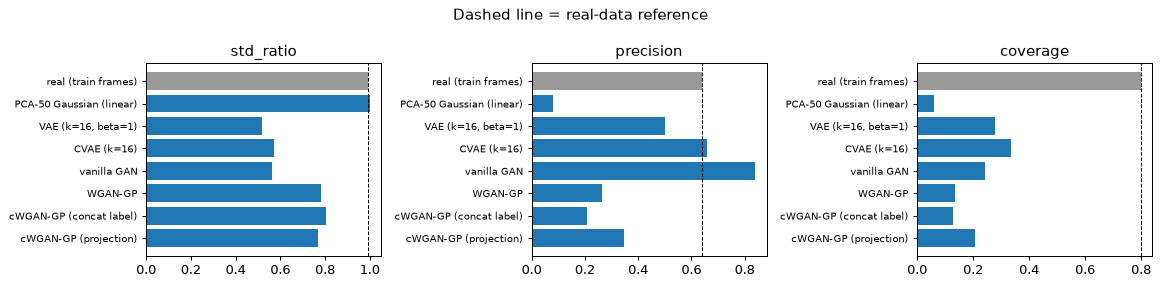

In [11]:
metrics = ["std_ratio", "precision", "coverage"]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
for ax, m in zip(axes, metrics):
    vals = compare[m]
    ax.barh(range(len(vals)), vals.values, color=["0.6"] + ["tab:blue"] * (len(vals) - 1))
    ax.set_yticks(range(len(vals))); ax.set_yticklabels(vals.index, fontsize=8)
    ax.axvline(compare.loc["real (train frames)", m], color="k", ls="--", lw=0.8)
    ax.set_title(m); ax.invert_yaxis()
fig.suptitle("Dashed line = real-data reference"); fig.tight_layout(); plt.show()

**Reading the comparison.**

* Compared with the VAE, the Wasserstein GANs raise `std_ratio` toward 1 and lower `mmd`: their samples carry realistic fluctuations, not the average frame.
* No single GAN wins on every axis. The vanilla GAN has the **highest precision** of any model, because it collapsed onto one variant and makes only frames it is sure of. The WGAN-GPs cover both variants but spill samples between conformational states.
* Getting even this far needed many careful choices: critic updates per generator step, a gradient penalty, Adam with $\beta_1 = 0$, and a projection critic for conditioning.
* A GAN has **no likelihood**, so there is no principled way to tell whether it is missing rare conformations, short of computing coverage as we did.

These three problems (fragile training, mode dropping, no likelihood) motivated a return to likelihood-based models that **does not** blur: **denoising diffusion models**, in **Notebook 04**.

## Challenge Problem 1: Is the critic necessary to train often?

Retrain the *unconditional* WGAN-GP with `n_critic=1` (critic and generator updated equally often) for 40 epochs. Compare the critic-loss curve and the final `coverage` with the `n_critic=5` model above. What does the result tell you about why the critic must be kept close to optimal?

In [12]:
# Start your code here

### Challenge Problem 1 Solution

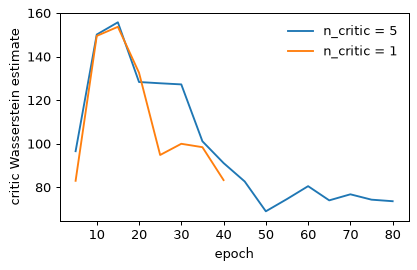

,precision,coverage,std_ratio,mmd
model,,,,
WGAN-GP n_critic=1 (40 ep),0.296,0.039,0.682,0.079
WGAN-GP n_critic=5 (80 ep),0.266,0.136,0.784,0.023


In [13]:
G_1, log_1 = train_wgan_gp(epochs=40, n_critic=1)
with torch.no_grad():
    s1 = G_1(torch.randn(len(data.X_test), Z_DIM), None).numpy()
r1 = sc.evaluate(s1, name="WGAN-GP n_critic=1 (40 ep)", store=False)
fig, ax = plt.subplots(figsize=(5, 3))
ax.plot(log_w.index, log_w["loss_D"], label="n_critic = 5")
ax.plot(log_1.index, log_1["loss_D"], label="n_critic = 1")
ax.set_xlabel("epoch"); ax.set_ylabel("critic Wasserstein estimate"); ax.legend(frameon=False)
plt.show()
pd.DataFrame([r1, sc.rows[[r["model"] for r in sc.rows].index("WGAN-GP")] | {"model": "WGAN-GP n_critic=5 (80 ep)"}]).set_index("model")[["precision", "coverage", "std_ratio", "mmd"]].round(3)

## Challenge Problem 2: Walking between variants

With the **conditional** generator, fix 200 noise vectors $z$ and feed *soft* labels $c = (1-\alpha, \alpha)$ for $\alpha \in [0, 1]$ in 11 steps. For each $\alpha$, report the fraction of samples the judge classifies as SARS-CoV-2. Is the transition gradual or abrupt? What would a gradual transition mean, physically, for interface frames "between" the two viruses?

In [14]:
# Start your code here

### Challenge Problem 2 Solution

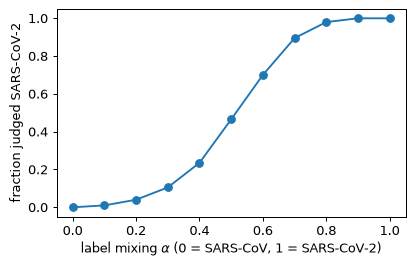

In [15]:
set_seed(1)
z = torch.randn(200, Z_DIM)
alphas = np.linspace(0, 1, 11)
frac = []
with torch.no_grad():
    for a in alphas:
        c = torch.tensor([[1 - a, a]], dtype=torch.float32).repeat(200, 1)
        frac.append(sc.judge.predict(gen_c.net(torch.cat([z, c], 1)).numpy()).mean())
fig, ax = plt.subplots(figsize=(5, 3))
ax.plot(alphas, frac, "o-"); ax.set_xlabel(r"label mixing $\alpha$ (0 = SARS-CoV, 1 = SARS-CoV-2)")
ax.set_ylabel("fraction judged SARS-CoV-2"); plt.show()

A generator is free to do anything for labels it never saw (soft labels are out of distribution). Here the fraction follows an S-shaped curve: samples stay SARS-CoV-like up to $\alpha \approx 0.3$, switch over a fairly narrow window around $\alpha \approx 0.5$, and are SARS-CoV-2-like beyond $\alpha \approx 0.8$. The model has learned two separate modes joined by a short transition, not a smooth continuum. Biologically this is sensible: the two RBDs differ in sequence, so no real interface lies "halfway" between them, and the in-between samples should not be read as physical intermediates.

## Save the scorecard

In [16]:
print("saved", sc.save("03_GAN"))

saved results/scorecard.csv


## Summary

* A GAN replaces an explicit likelihood with a learned discriminator, which gives sharper samples than a VAE.
* The vanilla GAN shows the classic failure modes: uninformative losses and **mode collapse**.
* WGAN-GP's critic estimates the Wasserstein distance, which stays informative without distribution overlap; the gradient penalty enforces the required Lipschitz constraint.
* Conditioning on a label lets us generate a requested variant, verified by an independent classifier. Naive label concatenation is ignored by the critic; a projection critic fixes this.
* GANs remain fragile and have no likelihood, which motivates diffusion models.

## References

* Goodfellow I. *et al.* (2014) Generative adversarial nets. *NeurIPS*.
* Mirza M., Osindero S. (2014) Conditional generative adversarial nets. arXiv:1411.1784.
* Miyato T., Koyama M. (2018) cGANs with projection discriminator. *ICLR*.
* Arjovsky M., Chintala S., Bottou L. (2017) Wasserstein generative adversarial networks. *ICML*.
* Gulrajani I. *et al.* (2017) Improved training of Wasserstein GANs. *NeurIPS*.
* Salimans T. *et al.* (2016) Improved techniques for training GANs. *NeurIPS*.